# Market-making baselines on Hyperliquid HYPE: microprice + Avellaneda–Stoikov reservation quotes

**What this is.** A baseline *analysis*, not a backtest you should trust for PnL. Two textbook methods,
each measured the same way, so that any idea you have later can be dropped into the same slot and compared
against them:

1. **Fair value: the microprice.** Two versions: the *weighted mid* (size-weighted touch) and Stoikov's
   (2018) *micro-price* (expected mid in the long run, estimated from a Markov chain on imbalance and spread).
   Scored on how well each predicts the mid **100–500 ms** ahead, against the plain mid.
2. **Quoting: Avellaneda–Stoikov (2008) reservation bid/ask.** Quotes are centred on a *reservation price*
   that is skewed away from the current inventory, with a spread set by volatility, risk aversion and how fast fill
   probability decays with distance. Requoted every **Δ ∈ {100, 250, 500} ms**. Scored on fills, markouts and
   mark-to-mid PnL against a "join the touch" quoter.

**Data.** `market_data_v2` (VM collector), HL `l1` = `bbo` channel (event-driven, has sizes) and HL `trades`
(with aggressor side). The old `data/HYPERLIQUID` book is ~5.4 s snapshots. That's too coarse for 100–500 ms quoting, so it's unused.

**Status:** exploratory and *unregistered*. There's no hypothesis card: this establishes baselines and
makes no prediction. It was built before `qrlib` existed and hasn't been migrated, so it carries its own truncation
test (§6), fill bounds (§7) and trial counter (§9).

**Weak points up front**
* Very little data: the covered segments printed in §2 (a weekend, with holes), and one 60/40 chronological split.
* Fills are *simulated* from public trades. There's no queue position, our orders don't affect the book, and partial fills are ignored.
  The truth is somewhere between the `through` (pessimistic) and `touch` (optimistic) bounds.
* The HYPE spread is 1 tick (~0.13 bps) 73% of the time, so at the touch almost everything hinges on queue position, which we can't see.
* **Fill timing is not feasible as built (biggest weak point).** Everything runs on the VM clock (`ts_recv`), and HL data lands
  ~300 ms after the block. With `ORDER_DELAY_MS` = 0, a quote decided at τ is filled by trades *received* in (τ, τ+Δ], but those
  trades executed on the exchange ~300 ms earlier, before the quote was sent. In exchange time this is a zero-latency quoter.
  Worse, the book update for a block can arrive before that block's trade print, so some quotes are placed after seeing the
  post-trade book and then "filled" by that trade. A feasible setting needs `ORDER_DELAY_MS` ≥ feed lag + order entry.

## Summary (run of 2026-10-22; sample 2026-10-18 03:14 → 2026-10-20 00:30 UTC; 43.6 covered h; n_trials = 27 this run)
**Bottom line:** on HYPE, no quoter here makes money under either fill bound, even before fees. The extended micro-price
beats the mid by ~3–4% MSE at 250–500 ms; at 100 ms nothing beats the mid by more than 1%.

**Read this first.** The quoting results use `ORDER_DELAY_MS` = 0 on the VM clock. That lets a quote be filled by trades
that executed on the exchange ~300 ms *before* the quote was sent, so the quoting section is a zero-latency simulation,
not an optimistic one. "No quoter makes money" probably survives a realistic delay, but that's untested. The **relative**
quoting claims (faster requoting loses less; centring on the micro-price loses less) were measured under infeasible
timing; don't rely on them until they're rerun with `ORDER_DELAY_MS` ≥ feed lag + order entry. The fair-value section
(§3.1) is not affected: it only compares what's known at t with the mid known at t + h.

**Data.** 43.6 covered hours in three segments. Two feed holes on Monday 10-19 (12:16–13:32 and 14:00–14:23 UTC) are
excluded, and inventory is flattened at each. Train (26.2 h): Sunday 03:14 → Monday 05:24 UTC. Test (17.4 h): Monday
05:24 → Tuesday 00:30 UTC, so it now includes Monday's European and US hours. This is still one 60/40 split.
Clock: VM (`ts_recv`), HL data lands a median 305 ms after the block (min 191, p99 812).

**Fair value (test, n = 627,820): MSE skill vs the plain mid, 95% block-bootstrap CI**

| | 100 ms | 250 ms | 500 ms |
|---|---|---|---|
| Weighted mid | −15.9% [−17.9, −13.9] | +1.5% [0.7, 2.2] | +3.3% [2.9, 3.8] |
| Micro-price (textbook) | +0.9% [0.9, 1.0] | +1.0% [1.0, 1.1] | +0.9% [0.9, 0.9] |
| Micro-price (extended) | −4.9% [−5.2, −4.6] | +2.9% [2.6, 3.2] | **+4.1% [3.9, 4.3]** |

The textbook micro-price only allows ±1-tick moves per step, so its adjustment is 1.8–8.1× too small (calibration
slopes). The extended version (±4 ticks) is my modification, not the textbook method; it over-reacts at 100 ms (slope
0.32) and is slightly undersized at 500 ms (slope 1.43).

**Quoting** (zero-latency fills, see "Read this first"; 1 HYPE per quote, mark-to-mid, no fees)
* All 18 combinations lose money; every PnL/h CI excludes zero (−$2.1 to −$5.4 per hour).
* Spread captured at the fill is negative for **every** strategy now (−0.08 to −0.68 bps), so read markouts, not capture.
* AS(micro-price) vs AS(mid), 1 s markout under `touch`: −0.41 vs −0.56 (Δ 100), −0.51 vs −0.67 (Δ 250), −0.65 vs −0.77 bps
  (Δ 500); the CIs don't overlap. Under `through` the gap is 0.03–0.04 bps and the CIs overlap.
* Faster requoting loses less per fill: AS(micro-price) [touch] −0.41 / −0.51 / −0.65 bps at Δ = 100 / 250 / 500 ms.
* Join-the-touch is the bound-sensitive one: −0.25 to −0.33 bps under `touch`, −0.91 to −1.05 under `through`.

**What changed vs the 10-20 run** (26.8 h, test = Sunday evening to Monday morning)
* Fair value is stable: the extended micro-price went from +2.9% / +3.8% to +2.9% / +4.1% at 250 / 500 ms. The weighted mid's
  250 ms skill moved from +0.3% (CI spanning 0) to +1.5% [0.7, 2.2].
* Quoting got worse across the board: e.g. AS(micro-price) [touch] Δ 250 went from −0.34 to −0.51 bps at 1 s, and AS capture
  at the fill turned negative. The test period changed (it now includes Monday's US hours), so this is a different sample,
  not more of the same one.
* Trials: 27 variants in this run; 108 evaluated across the three runs of this notebook (54 + 27 + 27).

Details are in §10 Findings; the full assumption list and open questions are at the end.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.dataset as ds

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 4)

# dataviz reference palette, fixed order: blue, orange, aqua = the three quoting strategies / fair values
C1, C2, C3, C_INK, C_MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#0b0b0b", "#8a8984"
# orange = touch quoter / weighted mid, blue = AS(mid), aqua = AS(micro-price) / extended micro-price, grey = textbook micro-price
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6,
    "axes.edgecolor": C_MUTED, "axes.labelcolor": C_INK, "lines.linewidth": 2, "font.size": 9,
})

## 1. KNOBS
Every tunable choice lives here. `# ASSUMPTION:` marks choices you didn't specify.

In [2]:
DATA_ROOT = Path("../market_data_v2/normalized")
SYMBOL = "HYPE-USD-PERP"
DATA_END_UTC = "2026-10-20 00:30"   # ASSUMPTION: sample frozen here (local data ends 00:35; was 2026-10-19 06:00 in the 10-20 run) so the findings match while the local sync is still adding files; None = use all
TRAIN_FRAC = 0.6            # ASSUMPTION: chronological 60/40 split of *covered* time; every parameter is fit on train only.
# Coverage: the local copy can have holes (missing hours, outages, a sync still in progress). We only work inside
# segments where both feeds are live.
MAX_L1_GAP_MS = 30_000      # ASSUMPTION: no HL bbo update for this symbol for 30 s = feed hole (normal median gap ~130 ms)
MAX_TR_GAP_MS = 120_000     # ASSUMPTION: no HL trade for 2 min = trade feed hole (normal rate ~1.6/s)
MIN_SEG_MS = 10 * 60_000    # ASSUMPTION: ignore covered segments shorter than 10 min

# --- clock / latency ---
# Everything is on the VM clock: the book is known when it arrives (ts_recv), and fills are judged on trade arrival.
ORDER_DELAY_MS = 0.0   # ASSUMPTION: a quote can be hit by trades *received* right after the decision. Trades arrive ~300 ms
                       # after they execute, so at 0 the quote is filled by trades that happened before it was sent
                       # (infeasible). A feasible value is >= feed lag + order entry; Mark to choose.
SCENARIOS = {"measured ts_recv": dict(clock="recv", order_delay_ms=ORDER_DELAY_MS)}
REF = "measured ts_recv"   # the scenario the plots use

# --- fair value (microprice) ---
FV_HORIZONS_MS = [100, 250, 500]   # the MFT window you asked for
FV_GRID_MS = 100                   # evaluate fair values on a 100 ms decision grid
MP_DT_MS = 100                     # ASSUMPTION: Stoikov chain sampled every 100 ms (one step = the shortest horizon)
N_IMB = 10                         # ASSUMPTION: imbalance in 10 equal-width buckets on [0,1] (equal width keeps the symmetrisation exact)
# Two versions of Stoikov's estimator:
#   textbook: as in the paper's code; mid moves of at most 1 tick per step, spreads of 1-2 ticks.
#   extended: HYPE moves ~1.5 ticks per 100 ms, so the textbook version throws away the big moves, which are the ones the
#             imbalance predicts. ASSUMPTION: moves up to 4 ticks per step and spreads up to 4 ticks (98.9% of train
#             transitions). Moves that land in a wider spread count as a final move (no continuation).
MP_VARIANTS = {"micro-price (textbook)": dict(n_spread=2, max_move=1),
               "micro-price (extended)": dict(n_spread=4, max_move=4)}
MP_FOR_QUOTES = "micro-price (extended)"   # ASSUMPTION: the variant that AS(micro-price) centres on

# --- quoting (Avellaneda–Stoikov) ---
QUOTE_DTS_MS = [100, 250, 500]     # requote interval Δ
QUOTE_SZ = 1.0                     # ASSUMPTION: 1 HYPE per quote (~$79; median touch size is ~44 HYPE)
Q_MAX = 5                          # ASSUMPTION: inventory limit in lots; at the limit the side that adds inventory is pulled
TAU_MS = 1000.0                    # ASSUMPTION: AS horizon (T - t) held fixed at 1 s (rolling, infinite-horizon use of the formula)
SKEW_AT_QMAX_TICKS = 2.0           # ASSUMPTION: gamma chosen so that at |q| = Q_MAX the reservation price moves 2 ticks
K_FIT_DELTAS = np.arange(0.5, 5.0, 1.0)   # distances from mid (ticks) used to fit fill intensity lambda(d) = A exp(-k d)
MAKER_FEE_BPS = 0.0                # ASSUMPTION: fees/rebates ignored; set your own tier here
MARKOUT_MS = [100, 250, 500, 1000, 5000]

# --- uncertainty ---
BOOT_REPS = 500
FV_BOOT_BLOCK = 600                # 600 x 100 ms = 1 min blocks for fair-value losses
FILL_BOOT_BLOCK = 50               # consecutive fills per block for markouts
PNL_BAR_MS = 60_000                # PnL increments per minute ...
PNL_BOOT_BLOCK = 10                # ... bootstrapped in 10-minute blocks
SEED = 0

TRIALS = []
def log_trial(**kw):
    TRIALS.append(kw)

## 2. Data
* HL trades and l1 replay a snapshot on every websocket (re)subscribe. Rows stamped before their connection opened are dropped.
* Prices are converted to **integer ticks** so that "at the bid" vs "through the bid" comparisons are exact.
* **Coverage.** The work happens only inside *segments* where both the bbo and the trade feed are live (no hole longer than
  `MAX_L1_GAP_MS` / `MAX_TR_GAP_MS`). Inventory is flattened at mid at the end of each segment. The train/test split is
  60% of *covered* time, not of wall-clock time.

In [3]:
def _path_sym(s):
    return s.replace(":", "")    # rclone writes ':' as U+F03A in Windows folder names

def load(table, venue, symbol, cols):
    p = DATA_ROOT / f"table={table}" / f"venue={venue}" / f"symbol={_path_sym(symbol)}"
    return ds.dataset(p, format="parquet", partitioning="hive").to_table(columns=cols).to_pandas()

sess = ds.dataset(DATA_ROOT / "table=sessions", format="parquet", partitioning="hive").to_table().to_pandas()
hl_open = (sess[(sess.venue == "HYPERLIQUID") & (sess.kind == "ws") & (~sess.resumed)]
           .groupby("ordinal").opened_ns.min())

l1 = load("l1", "HYPERLIQUID", SYMBOL, ["ts_exch_ns", "ts_recv_ns", "conn_ordinal", "bid_px", "bid_sz", "ask_px", "ask_sz"])
tr = load("trades", "HYPERLIQUID", SYMBOL, ["ts_exch_ns", "ts_recv_ns", "conn_ordinal", "price", "size", "aggressor"])
for name, df in (("l1", l1), ("trades", tr)):
    bad = df.ts_exch_ns < df.conn_ordinal.map(hl_open)
    if DATA_END_UTC:
        bad |= df.ts_exch_ns >= pd.Timestamp(DATA_END_UTC).value
    print(f"{name}: dropped {bad.sum()} rows (subscribe replays, or after DATA_END_UTC)")
    df.drop(index=df.index[bad], inplace=True)

sp = l1.ask_px - l1.bid_px
TICK = float(np.round(sp[sp > 0].min(), 10))
l1 = l1[(l1.bid_px > 0) & (l1.ask_px > l1.bid_px)].copy()   # drop crossed/empty books
l1["b"] = np.round(l1.bid_px / TICK).astype(np.int64)
l1["a"] = np.round(l1.ask_px / TICK).astype(np.int64)
tr["p"] = np.round(tr.price / TICK).astype(np.int64)
tr["side"] = np.where(tr.aggressor == "buy", 1, -1)          # +1 = buyer lifted the ask, -1 = seller hit the bid
for df in (l1, tr):
    df["t_exch"] = df.ts_exch_ns / 1e6
    df["t_recv"] = df.ts_recv_ns / 1e6
l1 = l1.sort_values(["t_exch", "t_recv"], kind="stable").reset_index(drop=True)
tr = tr.sort_values(["t_exch", "t_recv"], kind="stable").reset_index(drop=True)

def live_intervals(t, max_gap):
    """Maximal intervals where consecutive events are <= max_gap apart."""
    t = np.sort(t)
    br = np.where(np.diff(t) > max_gap)[0]
    return np.c_[np.r_[t[0], t[br + 1]], np.r_[t[br], t[-1]]]

def intersect(A, B):
    out = []
    for a0, a1 in A:
        for b0, b1 in B:
            lo, hi = max(a0, b0), min(a1, b1)
            if hi > lo:
                out.append((lo, hi))
    return np.array(out)

SEGS = intersect(live_intervals(l1.t_exch.values, MAX_L1_GAP_MS), live_intervals(tr.t_exch.values, MAX_TR_GAP_MS))
SEGS = SEGS[(SEGS[:, 1] - SEGS[:, 0]) >= MIN_SEG_MS]
cov = np.cumsum(SEGS[:, 1] - SEGS[:, 0])
j = int(np.searchsorted(cov, TRAIN_FRAC * cov[-1]))
T_SPLIT = SEGS[j, 1] - (cov[j] - TRAIN_FRAC * cov[-1])          # the time where 60% of covered time is reached
T0, T1 = SEGS[0, 0], SEGS[-1, 1]
PX_REF = float(l1.bid_px.median())
print(f"{SYMBOL}: tick={TICK} (~{TICK / PX_REF * 1e4:.3f} bps), {len(l1):,} l1 rows, {len(tr):,} trades")
print(pd.DataFrame({"from": pd.to_datetime(SEGS[:, 0], unit="ms"), "to": pd.to_datetime(SEGS[:, 1], unit="ms"),
                    "hours": (SEGS[:, 1] - SEGS[:, 0]) / 3.6e6}).round(2).to_string())
print(f"covered {cov[-1] / 3.6e6:.2f} h of {(T1 - T0) / 3.6e6:.2f} h wall-clock; "
      f"train/test split at {pd.to_datetime(T_SPLIT, unit='ms')} (train {TRAIN_FRAC * cov[-1] / 3.6e6:.2f} h, "
      f"test {(1 - TRAIN_FRAC) * cov[-1] / 3.6e6:.2f} h)")
print("spread (ticks) share:", ((l1.a - l1.b).value_counts(normalize=True).sort_index().head(5)).round(3).to_dict())

def grid(t_lo, t_hi, step, pad=0.0, segs=SEGS):
    """Decision times every `step` ms inside covered segments within [t_lo, t_hi), with t + pad still inside the
    segment. Returns (times, segment id). ASSUMPTION: coverage is treated as known (it is bookkeeping, not a signal)."""
    ts, sid = [], []
    for k, (s0, s1) in enumerate(segs):
        lo, hi = max(s0, t_lo), min(s1, t_hi) - pad
        if hi > lo:
            g = np.arange(lo, hi, step)
            ts.append(g); sid.append(np.full(len(g), k))
    return (np.concatenate(ts), np.concatenate(sid)) if ts else (np.array([]), np.array([], int))

l1: dropped 2365 rows (subscribe replays, or after DATA_END_UTC)
trades: dropped 853 rows (subscribe replays, or after DATA_END_UTC)


HYPE-USD-PERP: tick=0.001 (~0.127 bps), 782,365 l1 rows, 386,011 trades
                           from                      to  hours
0 2026-10-18 03:14:22.028000000 2026-10-19 12:16:47.613  33.04
1 2026-10-19 13:32:33.819000000 2026-10-19 14:00:01.561   0.46
2 2026-10-19 14:23:53.441999756 2026-10-20 00:29:58.372  10.10
covered 43.60 h of 45.26 h wall-clock; train/test split at 2026-10-19 05:23:56.982200195 (train 26.16 h, test 17.44 h)
spread (ticks) share: {1: 0.726, 2: 0.061, 3: 0.044, 4: 0.037, 5: 0.031}


### 2.1 Clock views
A *view* holds the book and the trades on the VM clock:
* `known[i]` is when book row i becomes usable (its `ts_recv`). It's a prefix max, so a row never becomes known before an earlier row.
* `tt` is the time used to decide whether a trade hits a resting quote (its `ts_recv`).

In [4]:
class View:
    def __init__(self, name, cfg, l1, tr, seed=SEED):
        self.name, self.cfg = name, cfg
        known = l1.t_recv.values
        self.tt = tr.t_recv.values
        self.live_lo, self.live_hi = cfg["order_delay_ms"], 0.0   # quote live from decision + order delay to the next decision
        o = np.argsort(known, kind="stable")
        self.known = np.maximum.accumulate(known[o])
        self.b, self.a = l1.b.values[o], l1.a.values[o]
        self.bs, self.as_ = l1.bid_sz.values[o], l1.ask_sz.values[o]
        ot = np.argsort(self.tt, kind="stable")
        self.tt, self.tp, self.ts, self.tsz = self.tt[ot], tr.p.values[ot], tr.side.values[ot], tr["size"].values[ot]

    def asof(self, q):
        """Index of the last book row known at time q (-1 if none)."""
        return np.searchsorted(self.known, q, "right") - 1

    def book_at(self, q):
        i = self.asof(q)
        ok = i >= 0
        i = np.clip(i, 0, None)
        out = dict(b=self.b[i], a=self.a[i], bs=self.bs[i], as_=self.as_[i])
        for k in out:
            out[k] = np.where(ok, out[k], np.nan) if out[k].dtype.kind == "f" else out[k]
        return out, ok

    def mid2_at(self, q):
        """2 x mid in ticks (an integer), as known at q."""
        i = np.clip(self.asof(q), 0, None)
        return (self.b[i] + self.a[i]).astype(float)

    def truncated(self, cut):
        """Same view with everything known/traded after `cut` deleted (for the leakage test)."""
        v = object.__new__(View)
        v.__dict__.update(self.__dict__)
        mb, mt = self.known <= cut, self.tt <= cut
        v.known, v.b, v.a, v.bs, v.as_ = self.known[mb], self.b[mb], self.a[mb], self.bs[mb], self.as_[mb]
        v.tt, v.tp, v.ts, v.tsz = self.tt[mt], self.tp[mt], self.ts[mt], self.tsz[mt]
        return v

VIEWS = {nm: View(nm, cfg, l1, tr) for nm, cfg in SCENARIOS.items()}
lag = (l1.t_recv - l1.t_exch)
print(f"HL ts_recv - ts_exch: min {lag.min():.0f} ms, median {lag.median():.0f} ms, p99 {lag.quantile(.99):.0f} ms")

HL ts_recv - ts_exch: min 191 ms, median 305 ms, p99 812 ms


## 3. Method 1: the microprice (fair value)

The mid $M=(P^b+P^a)/2$ ignores the queue sizes $Q^b, Q^a$ at the touch. Define the **imbalance**
$$I=\frac{Q^b}{Q^b+Q^a}\in[0,1].$$
A big bid queue against a thin ask queue ($I\to1$) suggests the next mid move is up.

**(a) Weighted mid** (the "naive microprice"):
$$P^{w} = I\,P^a + (1-I)\,P^b = M + \frac{S}{2}(2I-1),\qquad S=P^a-P^b .$$
It jumps all the way to the ask when $I=1$. Stoikov shows it is *not* a martingale: it is noisy and over-reacts.

**(b) Stoikov micro-price.** Define it as the mid's expected value in the long run, given today's state:
$$P^{\text{micro}}=\lim_{n\to\infty}\mathbb E[M_{\tau_n}\mid I, S] = M + g(I,S),$$
where $\tau_n$ are the times the mid changes. Discretise the state $x=(S,\ I\text{-bucket})$ and sample the book every
`MP_DT_MS`. Between samples, either the mid stays put and the state moves ($x\to y$, matrix $Q$), or the mid moves by
$k\in K=\{\pm\tfrac12,\pm1\}$ ticks. Then:
* $R_1$ is the matrix of mid-move probabilities, and $G_1=(I-Q)^{-1}R_1K$ is the expected size of the first mid move;
* $T$ is the matrix of state transitions *on* a move, and $B=(I-Q)^{-1}T$ is the state after the first move;
* the adjustment is $g=\sum_{i\ge0}B^iG_1$.

The data are **symmetrised** (each row is added again with $I\to1-I$, $\Delta M\to-\Delta M$), which forces $g$ to be
antisymmetric so that the sum converges. Everything is estimated on **train**. States never seen in train, and spreads
wider than the modelled ones, fall back to $g=0$ (the mid).

**Two versions** (`MP_VARIANTS`):
* *textbook*: as in Stoikov's code, $K=\{\pm\frac12,\pm1\}$ ticks and spreads of 1–2 ticks. Transitions outside that are dropped.
* *extended*: HYPE's mid moves ~1.5 ticks per 100 ms, and the moves the textbook version drops are disproportionately the ones
  the imbalance predicts (a thin queue gets eaten and the mid jumps). This version keeps moves up to ±4 ticks and spreads
  up to 4 ticks. A move into a wider spread counts as a final move (it adds to $G_1$ but not to $B$).

The plot below also shows the **realised** mean mid change 500 ms ahead by state, on train. A fair value that hugs it is
anticipating the right amount.

**How it's scored.** On a 100 ms grid over **test**: forecast error $e = M_{t+h}-\text{FV}_t$ (ticks) for
$h\in\{100,250,500\}$ ms. *Skill* is $1-\text{MSE}(\text{FV})/\text{MSE}(\text{mid})$, with a 1-minute block-bootstrap CI.
*Calibration slope* is the no-intercept OLS of $M_{t+h}-M_t$ on $\text{FV}_t-M_t$: 1 = right size, < 1 = over-reacts.

In [5]:
def state_index(b, a, bs, as_, n_spread):
    """(spread ticks, imbalance bucket) -> flat state index; -1 if outside the modelled states."""
    s = (a - b).astype(int)
    imb = bs / (bs + as_)
    bk = np.clip((imb * N_IMB).astype(int), 0, N_IMB - 1)
    ok = (s >= 1) & (s <= n_spread) & np.isfinite(imb)
    return np.where(ok, (s - 1) * N_IMB + bk, -1), imb

def fit_one_microprice(view, t_lo, t_hi, n_spread, max_move):
    """Stoikov (2018) micro-price adjustment g[state] in ticks, from book samples with t in [t_lo, t_hi]."""
    g_t, _ = grid(t_lo, t_hi, MP_DT_MS, pad=MP_DT_MS)
    bk0, ok0 = view.book_at(g_t)
    bk1, ok1 = view.book_at(g_t + MP_DT_MS)
    x0, _ = state_index(bk0["b"], bk0["a"], bk0["bs"], bk0["as_"], n_spread)
    x1, _ = state_index(bk1["b"], bk1["a"], bk1["bs"], bk1["as_"], n_spread)
    dm = ((bk1["b"] + bk1["a"]) - (bk0["b"] + bk0["a"])) / 2.0          # mid change in ticks (multiple of 1/2)
    keep = ok0 & ok1 & (x0 >= 0) & (np.abs(dm) <= max_move)
    if max_move <= 1:
        keep &= x1 >= 0                                                 # textbook: both states must be modelled
    x0, x1, dm = x0[keep], x1[keep], dm[keep]
    # symmetrise: mirror the imbalance bucket and flip the move
    mir = lambda x: np.where(x >= 0, (x // N_IMB) * N_IMB + (N_IMB - 1 - x % N_IMB), -1)
    x0, x1, dm = np.r_[x0, mir(x0)], np.r_[x1, mir(x1)], np.r_[dm, -dm]
    n = N_IMB * n_spread
    K = np.array([k / 2 for k in range(-2 * max_move, 2 * max_move + 1) if k != 0])   # possible mid moves (ticks)
    Qc = np.zeros((n, n)); Rc = np.zeros((n, len(K))); Tc = np.zeros((n, n))
    st = (dm == 0) & (x1 >= 0)                 # no mid move, state changes x0 -> x1
    mv = dm != 0                               # mid moved by dm
    np.add.at(Qc, (x0[st], x1[st]), 1)
    np.add.at(Rc, (x0[mv], np.searchsorted(K, dm[mv])), 1)
    mvin = mv & (x1 >= 0)                      # ... and landed in a modelled state, so the chain continues from x1
    np.add.at(Tc, (x0[mvin], x1[mvin]), 1)
    seen = (Qc.sum(1) + Rc.sum(1)) > 0
    row = np.where(seen, Qc.sum(1) + Rc.sum(1), 1.0)[:, None]
    Q, R1, T = Qc / row, Rc / row, Tc / row    # Q + R1 rows sum to 1; T has at most the row mass of R1
    inv = np.linalg.pinv(np.eye(n) - Q)
    G1 = inv @ R1 @ K                          # expected size of the next mid move, from each state
    B = inv @ T                                # state right after the next mid move
    g, term = G1.copy(), G1.copy()
    for _ in range(500):                       # g = G1 + B G1 + B^2 G1 + ...
        term = B @ term
        g += term
        if np.abs(term).max() < 1e-10:
            break
    g[~seen] = 0.0
    return dict(g=g, seen=seen, n_spread=n_spread, n_obs=int(keep.sum()))

def fit_microprice(view, t_lo, t_hi):
    return {nm: fit_one_microprice(view, t_lo, t_hi, **cfg) for nm, cfg in MP_VARIANTS.items()}

FV_NAMES = ["mid", "weighted mid"] + list(MP_VARIANTS)

def fair_values(view, t, mp):
    """Mid, weighted mid and the Stoikov micro-prices at decision times t, all in ticks, from the book known at t."""
    bk, ok = view.book_at(t)
    mid = (bk["b"] + bk["a"]) / 2.0
    _, imb = state_index(bk["b"], bk["a"], bk["bs"], bk["as_"], 1)
    out = {"mid": mid, "weighted mid": mid + (bk["a"] - bk["b"]) / 2.0 * (2 * imb - 1)}
    for nm, fit in mp.items():
        x, _ = state_index(bk["b"], bk["a"], bk["bs"], bk["as_"], fit["n_spread"])
        out[nm] = mid + np.where(x >= 0, fit["g"][np.clip(x, 0, None)], 0.0)   # outside the modelled states -> mid
    return pd.DataFrame({**out, "spread": bk["a"] - bk["b"], "imb": imb, "ok": ok}, index=t)

MP = {nm: fit_microprice(v, T0, T_SPLIT) for nm, v in VIEWS.items()}
for nm, mps in MP.items():
    for var, fit in mps.items():
        print(f"[{nm}] {var}: fit on {fit['n_obs']:,} train transitions; states seen {fit['seen'].sum()}/{len(fit['g'])}")

[measured ts_recv] micro-price (textbook): fit on 800,236 train transitions; states seen 20/20
[measured ts_recv] micro-price (extended): fit on 864,849 train transitions; states seen 40/40


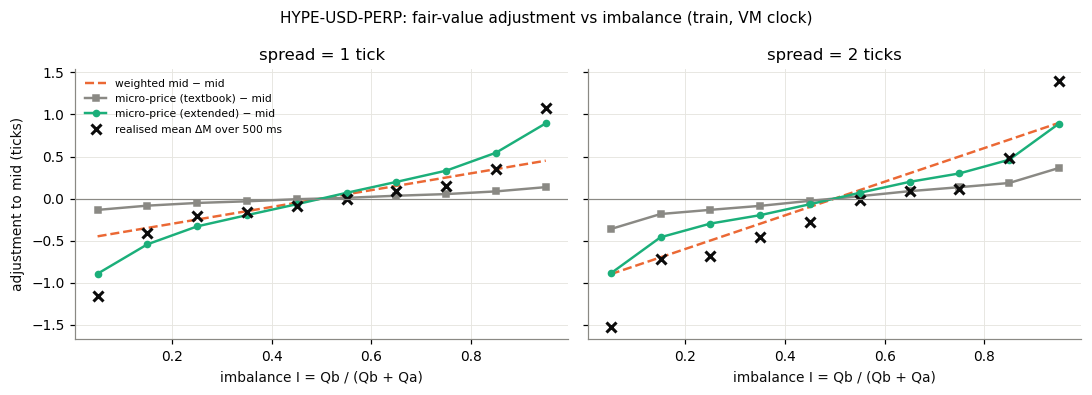

In [6]:
v0 = VIEWS[REF]
centres = (np.arange(N_IMB) + 0.5) / N_IMB
# realised mean mid change h ms ahead, by state, on TRAIN (what the fair values are trying to anticipate)
g_tr, _ = grid(T0, T_SPLIT, 100, pad=500)
bk_tr, _ = v0.book_at(g_tr)
x_tr, _ = state_index(bk_tr["b"], bk_tr["a"], bk_tr["bs"], bk_tr["as_"], 2)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for j in range(2):
    s = j + 1
    ax[j].plot(centres, s / 2 * (2 * centres - 1), color=C2, lw=1.6, ls="--", label="weighted mid − mid")
    for (var, fit), col, mk in zip(MP[v0.name].items(), [C_MUTED, C3], ["s", "o"]):
        ax[j].plot(centres, fit["g"][j * N_IMB:(j + 1) * N_IMB], marker=mk, color=col, ms=4, lw=1.6, label=f"{var} − mid")
    m = (x_tr >= j * N_IMB) & (x_tr < (j + 1) * N_IMB)
    real = pd.Series((v0.mid2_at(g_tr[m] + 500) - (bk_tr["b"][m] + bk_tr["a"][m])) / 2).groupby(x_tr[m] - j * N_IMB).mean()
    ax[j].plot(centres[real.index], real.values, "x", color=C_INK, ms=7, mew=2, label="realised mean ΔM over 500 ms")
    ax[j].axhline(0, color=C_MUTED, lw=0.8)
    ax[j].set(title=f"spread = {s} tick{'s' if s > 1 else ''}", xlabel="imbalance I = Qb / (Qb + Qa)")
ax[0].set_ylabel("adjustment to mid (ticks)")
ax[0].legend(frameon=False, fontsize=7)
fig.suptitle(f"{SYMBOL}: fair-value adjustment vs imbalance (train, VM clock)", fontsize=10)
plt.tight_layout(); plt.show()

### 3.1 Fair-value scoring (test)

In [7]:
def block_boot_ci(x, block, reps=BOOT_REPS, seed=SEED, stat=np.mean):
    x = np.asarray(x, float)
    n = len(x)
    if n < 2:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    block = max(1, min(block, n))
    nb = int(np.ceil(n / block))
    starts = rng.integers(0, n - block + 1, size=(reps, nb))
    idx = (starts[:, :, None] + np.arange(block)[None, None, :]).reshape(reps, -1)[:, :n]
    return tuple(np.percentile([stat(x[i]) for i in idx], [2.5, 97.5]))

def score_fv(view, mp):
    t, _ = grid(T_SPLIT, T1, FV_GRID_MS, pad=max(FV_HORIZONS_MS))
    F = fair_values(view, t, mp)
    F = F[F.ok]
    rows = []
    for h in FV_HORIZONS_MS:
        fut = view.mid2_at(F.index.values + h) / 2.0
        e_mid = fut - F["mid"].values
        for fv in FV_NAMES:
            e = fut - F[fv].values
            d = e_mid ** 2 - e ** 2                                  # > 0 where FV beats mid
            sig = F[fv].values - F["mid"].values
            slope = np.sum(sig * e_mid) / np.sum(sig ** 2) if np.sum(sig ** 2) > 0 else np.nan
            lo, hi = block_boot_ci(d / np.mean(e_mid ** 2), FV_BOOT_BLOCK)
            rows.append({"scenario": view.name, "horizon ms": h, "fair value": fv, "n": len(e),
                         "RMSE ticks": np.sqrt(np.mean(e ** 2)), "skill vs mid": 1 - np.mean(e ** 2) / np.mean(e_mid ** 2),
                         "skill CI lo": lo, "skill CI hi": hi, "calib. slope": slope,
                         "share mid moved": np.mean(e_mid != 0)})
            if fv != "mid":
                log_trial(part="fair value", scenario=view.name, fv=fv, horizon=h)
    return pd.DataFrame(rows)

fv_tab = pd.concat([score_fv(VIEWS[nm], MP[nm]) for nm in VIEWS]).set_index(["scenario", "horizon ms", "fair value"])
fv_tab

n  RMSE ticks  skill vs mid  skill CI lo  skill CI hi  calib. slope  share mid moved
scenario         horizon ms fair value                                                                                                       
measured ts_recv 100        mid                     627820      1.7976        0.0000       0.0000       0.0000           NaN           0.1355
                            weighted mid            627820      1.9348       -0.1585      -0.1794      -0.1389        0.3089           0.1355
                            micro-price (textbook)  627820      1.7893        0.0092       0.0088       0.0098        1.7814           0.1355
                            micro-price (extended)  627820      1.8412       -0.0491      -0.0522      -0.0458        0.3182           0.1355
                 250        mid                     627820      3.0045        0.0000       0.0000       0.0000           NaN           0.2430
                            weighted mid            627820      2.9818        0.0151       0.0073       0.0222        0.5508           0.2430
                            micro-price (textbook)  627820      2.9889        0.0103       0.0100       0.0108        4.5068           0.2430
                            micro-price (extended)  627820      2.9608        0.0289       0.0263       0.0316        0.7984           0.2430
                 500        mid                     627820      4.4692        0.0000       0.0000       0.0000           NaN           0.3343
                            weighted mid            627820      4.3940        0.0334       0.0286       0.0379        0.7489           0.3343
                            micro-price (textbook)  627820      4.4494        0.0089       0.0086       0.0092        8.1142           0.3343
                            micro-price (extended)  627820      4.3775        0.0406       0.0385       0.0429        1.4289           0.3343

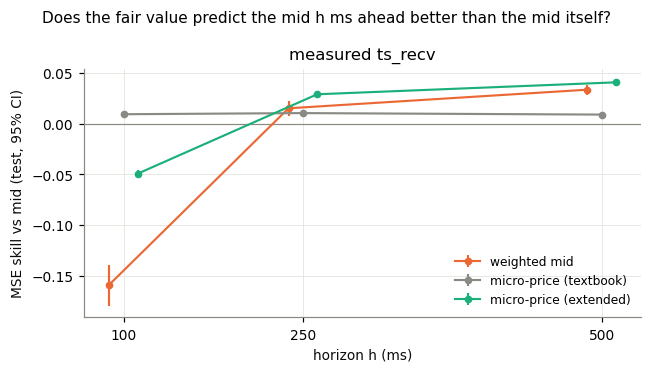

In [8]:
fig, ax = plt.subplots(1, len(VIEWS), figsize=(6, 3.4), sharey=True, squeeze=False)
ax = ax[0]
for a_, nm in zip(ax, VIEWS):
    for j, (fv, col) in enumerate(zip(FV_NAMES[1:], [C2, C_MUTED, C3])):
        sub = fv_tab.xs((nm, fv), level=("scenario", "fair value")).sort_index()
        x = np.array(FV_HORIZONS_MS) + (j - 1) * 12
        a_.errorbar(x, sub["skill vs mid"], yerr=[sub["skill vs mid"] - sub["skill CI lo"], sub["skill CI hi"] - sub["skill vs mid"]],
                    fmt="o-", color=col, ms=4, lw=1.4, capsize=0, label=fv)
    a_.axhline(0, color=C_MUTED, lw=0.8)
    a_.set(title=nm, xlabel="horizon h (ms)", xticks=FV_HORIZONS_MS)
ax[0].set_ylabel("MSE skill vs mid (test, 95% CI)")
ax[0].legend(frameon=False, fontsize=8)
fig.suptitle("Does the fair value predict the mid h ms ahead better than the mid itself?", fontsize=10)
plt.tight_layout(); plt.show()

## 4. Method 2: Avellaneda–Stoikov reservation bid/ask

AS model a dealer with CARA risk aversion $\gamma$ and inventory $q$ around a mid that's a Brownian motion with
volatility $\sigma$. Market orders hit a quote at distance $\delta$ from the mid at rate $\lambda(\delta)=A e^{-k\delta}$.
The approximate optimal quotes are:
$$r = s - q\,\gamma\sigma^2(T-t)\qquad\text{(reservation price)}$$
$$\delta^a+\delta^b = \gamma\sigma^2(T-t) + \frac{2}{\gamma}\ln\!\Big(1+\frac{\gamma}{k}\Big)\qquad\text{(total spread)}$$
$$\text{bid} = r - \tfrac12(\delta^a+\delta^b),\qquad \text{ask} = r + \tfrac12(\delta^a+\delta^b).$$

* **Reservation price $r$**: the price at which the dealer is indifferent to one more unit. Long inventory ($q>0$)
  pushes $r$ down, so the bid backs off and the ask leans in to sell. That skew is the whole inventory control.
* **Spread**: the first term is the inventory-risk premium; the second, $\approx 2/k$ for small $\gamma$, is the
  monopoly mark-up set by how fast fills fall off with distance.
* **$s$** is the fair value the quotes centre on. This is where Method 1 plugs in: **AS(mid)** vs **AS(micro-price)**.

**Parameters, all estimated on train in ticks and ms:**
* $\sigma^2$: mean squared 1 s mid change / 1000 (ticks²/ms).
* $k, A$: for each requote window Δ and each distance $d\in$ `K_FIT_DELTAS` from the mid at the window start, let
  $p(d)$ = fraction of windows in which an aggressor traded at $\ge$ mid + d (asks) or $\le$ mid − d (bids). Then
  $\lambda(d)\Delta = -\ln(1-p(d))$, and the OLS fit $\ln\lambda = \ln A - k d$ gives $k$. This is a *touch*-style fill intensity.
* $\gamma$: no natural value exists in ticks. ASSUMPTION: chosen so that at $|q|=Q_{\max}$ the reservation price is skewed by
  `SKEW_AT_QMAX_TICKS`: $\gamma = \text{skew}/(\sigma^2\tau Q_{\max})$.
* $T-t$: held at $\tau$ = `TAU_MS` (rolling use of the finite-horizon formula).

**On the tick grid.** bid = ⌊bid⌋ and ask = ⌈ask⌉ in ticks. Quotes are clamped to stay passive (bid ≤ best ask − 1,
ask ≥ best bid + 1). At $|q|\ge Q_{\max}$ the side that would add inventory is pulled.

**Baseline 0: join the touch.** bid = best bid, ask = best ask, with the same inventory limit and no skew.

In [9]:
def window_extremes(view, lo, hi):
    """For consecutive windows (lo_k, hi_k]: min price of seller-initiated trades and max of buyer-initiated ones (ticks)."""
    n = len(lo)
    smin = np.full(n, np.iinfo(np.int64).max); bmax = np.full(n, np.iinfo(np.int64).min)
    k = np.searchsorted(lo, view.tt, "left") - 1               # last window whose lo < t
    v = (k >= 0) & (view.tt <= hi[np.clip(k, 0, None)])
    sel, buy = v & (view.ts == -1), v & (view.ts == 1)
    np.minimum.at(smin, k[sel], view.tp[sel])
    np.maximum.at(bmax, k[buy], view.tp[buy])
    return smin, bmax

def fit_as_params(view, mp, dt, t_lo, t_hi):
    """sigma^2, k, A, gamma on [t_lo, t_hi] for requote interval dt."""
    g1, _ = grid(t_lo, t_hi, 1000.0, pad=1000.0)
    dm = (view.mid2_at(g1 + 1000) - view.mid2_at(g1)) / 2.0
    sig2 = np.mean(dm ** 2) / 1000.0                                   # ticks^2 per ms
    tau, _ = grid(t_lo, t_hi, dt, pad=dt)
    lo, hi = tau + view.live_lo, tau + dt + view.live_hi
    smin, bmax = window_extremes(view, lo, hi)
    mid = view.mid2_at(tau) / 2.0
    lam = []
    for d in K_FIT_DELTAS:
        p = 0.5 * (np.mean(bmax >= mid + d) + np.mean(smin <= mid - d))
        lam.append(-np.log(1 - p) / dt if 0 < p < 1 else np.nan)
    lam = np.array(lam)
    ok = np.isfinite(lam) & (lam > 0)
    slope, icpt = np.polyfit(K_FIT_DELTAS[ok], np.log(lam[ok]), 1)
    k, A = -slope, np.exp(icpt)
    gamma = SKEW_AT_QMAX_TICKS / (sig2 * TAU_MS * Q_MAX)
    half = 0.5 * (gamma * sig2 * TAU_MS + (2 / gamma) * np.log1p(gamma / k))
    return dict(dt=dt, sig2=sig2, k=k, A=A, gamma=gamma, half_spread=half, lam=lam)

AS = {(nm, dt): fit_as_params(VIEWS[nm], MP[nm], dt, T0, T_SPLIT) for nm in VIEWS for dt in QUOTE_DTS_MS}
pd.DataFrame({key: {"sigma (ticks/sqrt s)": np.sqrt(p["sig2"] * 1000), "k (1/tick)": p["k"], "A (1/ms)": p["A"],
                    "gamma": p["gamma"], "AS half-spread (ticks)": p["half_spread"],
                    "skew per lot (ticks)": p["gamma"] * p["sig2"] * TAU_MS}
              for key, p in AS.items()}).T

sigma (ticks/sqrt s)  k (1/tick)  A (1/ms)   gamma  AS half-spread (ticks)  skew per lot (ticks)
measured ts_recv 100                6.1548      0.4281    0.0003  0.0106                  2.5073                   0.4
                 250                6.1548      0.4145    0.0003  0.0106                  2.5824                   0.4
                 500                6.1548      0.3746    0.0003  0.0106                  2.8324                   0.4

In [10]:
def run_quotes(view, mp, prm, strategy, fill, t_lo, t_hi):
    """Simulate one quoter on decision grid [t_lo, t_hi). Returns per-decision frame and fills.
    strategy: 'touch' | 'AS(mid)' | 'AS(micro-price)'.  fill: 'through' (trade strictly beyond our price) | 'touch' (at or beyond)."""
    dt = prm["dt"]
    tau, seg = grid(t_lo, t_hi, dt, pad=dt)
    F = fair_values(view, tau, mp)
    lo, hi = tau + view.live_lo, tau + dt + view.live_hi
    smin, bmax = window_extremes(view, lo, hi)
    bb, ba = view.book_at(tau)[0]["b"], view.book_at(tau)[0]["a"]
    s_fv = F[MP_FOR_QUOTES].values if strategy == "AS(micro-price)" else F["mid"].values
    skew = prm["gamma"] * prm["sig2"] * TAU_MS
    strict = fill == "through"
    q, cash = 0.0, 0.0
    n = len(tau)
    out = np.empty((n, 4))                    # bid, ask, q at decision, cash at decision
    fills = []
    # trades per window, for the first qualifying trade time
    k_tr = np.searchsorted(lo, view.tt, "left") - 1
    in_w = (k_tr >= 0) & (view.tt <= hi[np.clip(k_tr, 0, None)])
    first = np.searchsorted(k_tr[in_w], np.arange(n), "left"); last = np.searchsorted(k_tr[in_w], np.arange(n), "right")
    tt_w, tp_w, ts_w = view.tt[in_w], view.tp[in_w], view.ts[in_w]
    fee = MAKER_FEE_BPS * 1e-4 * PX_REF / TICK       # per lot, in ticks
    ok_arr, mid_arr = F.ok.values, F["mid"].values
    last_mid = np.nan
    for i in range(n):
        if i > 0 and seg[i] != seg[i - 1] and q != 0:
            # ASSUMPTION: flatten at the last known mid when the data has a hole (costless; keeps outage jumps out of PnL)
            cash += q * last_mid; q = 0.0
        if ok_arr[i]:
            last_mid = mid_arr[i]
        if not ok_arr[i]:
            out[i] = (np.nan, np.nan, q, cash); continue
        if strategy == "touch":
            b, a = bb[i], ba[i]
        else:
            r = s_fv[i] - q * skew
            b = np.floor(r - prm["half_spread"]); a = np.ceil(r + prm["half_spread"])
            b, a = min(b, ba[i] - 1), max(a, bb[i] + 1)
        b = np.nan if q >= Q_MAX else b
        a = np.nan if q <= -Q_MAX else a
        out[i] = (b, a, q, cash)
        if first[i] == last[i]:
            continue
        sl = slice(first[i], last[i])
        for side, px, hit in ((+1, b, smin[i] < b if strict else smin[i] <= b),
                              (-1, a, bmax[i] > a if strict else bmax[i] >= a)):
            if np.isnan(px) or not hit:
                continue
            tp_s = tp_w[sl]
            if side == 1:                                     # our bid is hit by sellers ...
                m = (ts_w[sl] == -1) & ((tp_s < px) if strict else (tp_s <= px))
            else:                                             # ... our ask is lifted by buyers
                m = (ts_w[sl] == 1) & ((tp_s > px) if strict else (tp_s >= px))
            tf = tt_w[sl][np.argmax(m)]
            q += side * QUOTE_SZ
            cash -= side * px * QUOTE_SZ + fee * QUOTE_SZ
            fills.append((tf, side, px, tau[i]))
    D = pd.DataFrame(out, columns=["bid", "ask", "q", "cash"], index=tau)
    D["mid"] = F["mid"].values
    D["equity"] = D.cash + D.q * D.mid                       # mark-to-mid, ticks x lots
    Fl = pd.DataFrame(fills, columns=["t", "side", "px", "tau"])
    return D, Fl

STRATS = ["touch", "AS(mid)", "AS(micro-price)"]
FILLS = ["through", "touch"]

## 5. Fill model (both bounds, always reported)
A resting bid at price $b$ during its window $(\tau+L_{\text{order}},\ \tau+\Delta]$ (VM clock, $L_{\text{order}}$ = `ORDER_DELAY_MS`;
trades judged by when they were *received*) is filled (whole `QUOTE_SZ`) if a **seller-initiated** trade printed
* **through:** strictly below $b$. The level was swept, so wherever we sat in the queue we'd have been filled. *Pessimistic.*
* **touch:** at or below $b$. Assumes we were at the front of the queue. *Optimistic.*

The ask side mirrors this. At most one fill per side per window. Our orders don't change the book or anyone's behaviour.
The fill time (for markouts) is the first qualifying trade's time.

**Timing caveat.** A trade received at τ + ε executed on the exchange ~300 ms earlier. With $L_{\text{order}}$ = 0 the quote is
therefore filled by trades that happened before it was sent. For a fill to be feasible, $L_{\text{order}}$ has to be at least the
feed lag plus the order-entry time.

## 6. Leakage gate (truncation test)
Every decision at time τ may use only data known by τ. The test re-runs the whole pipeline on data with
**everything after a cut deleted**, including re-fitting the microprice and AS parameters, and checks that every decision
at or before the cut is unchanged. The check covers bid, ask, inventory and cash.
It also checks that the fair values on the FV grid are unchanged.

In [11]:
def pipeline(view, strategy, fill, dt):
    mp = fit_microprice(view, T0, T_SPLIT)
    prm = fit_as_params(view, mp, dt, T0, T_SPLIT)
    D, Fl = run_quotes(view, mp, prm, strategy, fill, T_SPLIT, T1)
    return D, mp

def truncation_test(view, strategy="AS(micro-price)", fill="touch", dt=250):
    D_full, mp_full = pipeline(view, strategy, fill, dt)
    for frac in (0.3, 0.7):
        cut = T_SPLIT + frac * (T1 - T_SPLIT)
        D_cut, mp_cut = pipeline(view.truncated(cut), strategy, fill, dt)
        keep = D_full.index.values <= cut
        a = D_full.loc[keep, ["bid", "ask", "q", "cash"]].values
        b = D_cut.reindex(D_full.index[keep])[["bid", "ask", "q", "cash"]].values
        assert np.allclose(a, b, equal_nan=True), f"LEAK in quotes ({view.name}, {strategy}, cut={cut})"
        tg, _ = grid(T_SPLIT, cut, FV_GRID_MS)
        fa = fair_values(view, tg, mp_full)[FV_NAMES].values
        fb = fair_values(view.truncated(cut), tg, mp_cut)[FV_NAMES].values
        assert np.allclose(fa, fb, equal_nan=True), f"LEAK in fair values ({view.name}, cut={cut})"
    return True

for nm, v in VIEWS.items():
    for st in STRATS:
        print(f"truncation test [{nm} | {st}]:", truncation_test(v, st))

truncation test [measured ts_recv | touch]: True


truncation test [measured ts_recv | AS(mid)]: True


truncation test [measured ts_recv | AS(micro-price)]: True


## 7. Quoting results (test)
Per (scenario × requote Δ × strategy × fill bound):
* **fills/h** and **share of decisions quoting each side**;
* **markout at H** (bps, per fill) = side × (mid at fill + H − fill price) / price. It splits into
  **spread capture** (mid at fill vs fill price, which we earn) and **adverse selection** (mid move after the fill, usually against us);
* **PnL/h** (mark-to-mid, USD, no fees) with a block-bootstrap CI on per-minute increments, plus mean |inventory|.

The `through` bound fills far less often. Conclusions that hold only under `touch` are queue-position bets.

In [12]:
def markouts(view, Fl):
    if len(Fl) == 0:
        return {}
    m0 = view.mid2_at(Fl.t.values) / 2.0
    out = {"capture": Fl.side.values * (m0 - Fl.px.values)}
    for H in MARKOUT_MS:
        out[H] = Fl.side.values * (view.mid2_at(Fl.t.values + H) / 2.0 - Fl.px.values)
    return {k: v * TICK / PX_REF * 1e4 for k, v in out.items()}       # bps

res_rows, RUNS = [], {}
for nm, view in VIEWS.items():
    for dt in QUOTE_DTS_MS:
        prm = AS[(nm, dt)]
        for st in STRATS:
            for fl in FILLS:
                D, Fl = run_quotes(view, MP[nm], prm, st, fl, T_SPLIT, T1)
                RUNS[(nm, dt, st, fl)] = (D, Fl)
                mk = markouts(view, Fl)
                hours = len(D) * dt / 3.6e6                        # covered hours (not wall-clock: the data has holes)
                eq = D.equity.ffill().values * TICK                    # USD
                bars = pd.Series(eq, index=D.index).groupby((D.index - D.index[0]) // PNL_BAR_MS).last().diff().dropna().values
                pnl_ci = np.array(block_boot_ci(bars, PNL_BOOT_BLOCK)) * 3.6e6 / PNL_BAR_MS
                row = {"scenario": nm, "Δ ms": dt, "strategy": st, "fill": fl, "fills": len(Fl), "fills/h": len(Fl) / hours,
                       "quoting bid %": 100 * D.bid.notna().mean(), "quoting ask %": 100 * D.ask.notna().mean(),
                       "mean |q| lots": D.q.abs().mean(), "PnL/h USD": (eq[-1] - eq[0]) / hours,
                       "PnL/h CI lo": pnl_ci[0], "PnL/h CI hi": pnl_ci[1]}
                if mk:
                    row["capture bps"] = mk["capture"].mean()
                    for H in (250, 1000, 5000):
                        row[f"markout {H}ms bps"] = mk[H].mean()
                    lo_, hi_ = block_boot_ci(mk[1000], FILL_BOOT_BLOCK)
                    row["mk1000 CI lo"], row["mk1000 CI hi"] = lo_, hi_
                res_rows.append(row)
                log_trial(part="quoting", scenario=nm, dt=dt, strategy=st, fill=fl)
res = pd.DataFrame(res_rows).set_index(["scenario", "Δ ms", "strategy", "fill"])
res

fills    fills/h  quoting bid %  quoting ask %  mean |q| lots  PnL/h USD  PnL/h CI lo  PnL/h CI hi  capture bps  markout 250ms bps  markout 1000ms bps  \
scenario         Δ ms strategy        fill                                                                                                                                                              
measured ts_recv 100  touch           through   6702   384.2939        86.3671        76.5569         3.4015    -3.4171      -4.2085      -2.6870      -0.5272            -0.7299             -0.9055   
                                      touch    32092  1840.1611        92.5238        72.6766         3.4239    -4.8529      -5.6491      -3.9819      -0.0826            -0.1766             -0.2510   
                      AS(mid)         through   6740   386.4728        95.0154        84.6120         2.7549    -2.3164      -2.9478      -1.7630      -0.3440            -0.5155             -0.6564   
                                      touch     8401   481.7149        95.5854        87.6873         2.6130    -2.5574      -3.2213      -1.9300      -0.2513            -0.4191             -0.5613   
                      AS(micro-price) through   6635   380.4521        95.9932        85.6212         2.7167    -2.0880      -2.7234      -1.5456      -0.3173            -0.4831             -0.6162   
                                      touch     9733   558.0920        98.8033        95.8428         2.0575    -2.0655      -2.6274      -1.5408      -0.1838            -0.3123             -0.4126   
                 250  touch           through   7120   408.2650        87.6630        77.2266         3.3459    -3.7415      -4.5734      -2.9859      -0.5972            -0.8078             -0.9770   
                                      touch    30474  1747.3972        92.6727        73.2865         3.4026    -5.1623      -5.9829      -4.3015      -0.1151            -0.2107             -0.2829   
                      AS(mid)         through   6860   393.3565        94.8577        84.6713         2.7571    -2.8787      -3.5907      -2.2437      -0.4455            -0.6265             -0.7673   
                                      touch     8336   477.9912        95.2782        87.4205         2.6311    -3.0818      -3.8099      -2.3962      -0.3458            -0.5229             -0.6652   
                      AS(micro-price) through   6681   383.0925        95.3889        85.4474         2.7553    -2.6352      -3.3712      -2.0119      -0.4173            -0.5911             -0.7252   
                                      touch     9653   553.5087        98.6756        96.0057         2.0760    -2.6554      -3.2588      -2.0654      -0.2700            -0.4105             -0.5143   
                 500  touch           through   7625   437.2237        89.1037        78.6286         3.2263    -4.4118      -5.2830      -3.6485      -0.6776            -0.8835             -1.0528   
                                      touch    28080  1610.1302        93.0498        74.0581         3.3738    -5.4001      -6.2143      -4.6101      -0.1524            -0.2512             -0.3250   
                      AS(mid)         through   6860   393.3580        94.6339        85.2562         2.7660    -3.3878      -4.1147      -2.7051      -0.5414            -0.7257             -0.8617   
                                      touch     8095   464.1739        95.3482        86.2175         2.6858    -3.5664      -4.3486      -2.8827      -0.4433            -0.6239             -0.7675   
                      AS(micro-price) through   6664   382.1192        95.1372        85.2626         2.7237    -3.1566      -3.8945      -2.4274      -0.5156            -0.6956             -0.8297   
                                      touch     8940   512.6269        97.7438        93.2800         2.3585    -3.1068      -3.7929      -2.4401      -0.3719            -0.5286             -0.6452   

                          

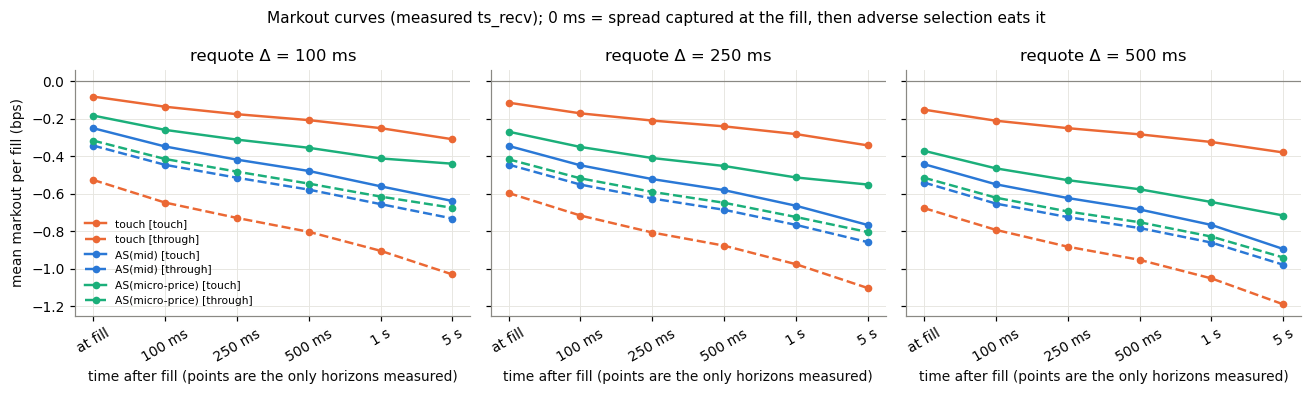

In [13]:
nm0 = REF
fig, ax = plt.subplots(1, len(QUOTE_DTS_MS), figsize=(12, 3.6), sharey=True)
xlab = ["at fill"] + [f"{H} ms" if H < 1000 else f"{H // 1000} s" for H in MARKOUT_MS]
for a_, dt in zip(ax, QUOTE_DTS_MS):
    for st, col in zip(STRATS, [C2, C1, C3]):
        for fl, ls in (("touch", "-"), ("through", "--")):
            mk = markouts(VIEWS[nm0], RUNS[(nm0, dt, st, fl)][1])
            if not mk:
                continue
            y = [mk["capture"].mean()] + [mk[H].mean() for H in MARKOUT_MS]
            a_.plot(range(len(y)), y, ls, marker="o", ms=4, color=col, lw=1.6, label=f"{st} [{fl}]")
    a_.axhline(0, color=C_MUTED, lw=0.8)
    a_.set_xticks(range(len(xlab)), xlab, rotation=30)
    a_.set(xlabel="time after fill (points are the only horizons measured)", title=f"requote Δ = {dt} ms")
ax[0].set_ylabel("mean markout per fill (bps)")
ax[0].legend(frameon=False, fontsize=7)
fig.suptitle(f"Markout curves ({nm0}); 0 ms = spread captured at the fill, then adverse selection eats it", fontsize=10)
plt.tight_layout(); plt.show()

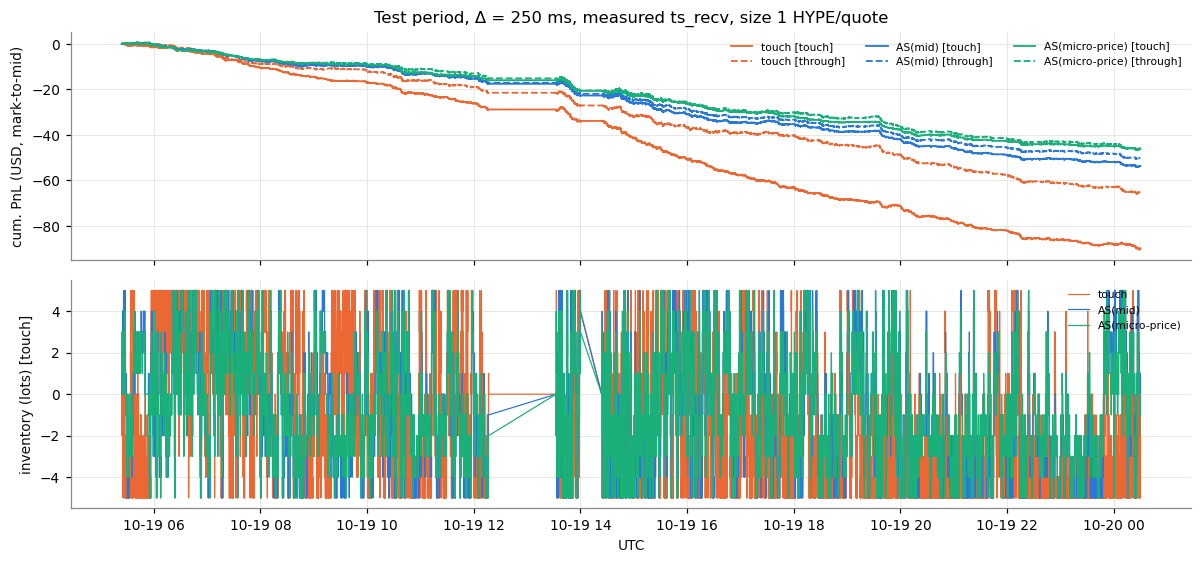

In [14]:
dt0 = 250
fig, ax = plt.subplots(2, 1, figsize=(11, 5.2), sharex=True)
for st, col in zip(STRATS, [C2, C1, C3]):
    for fl, ls in (("touch", "-"), ("through", "--")):
        D = RUNS[(nm0, dt0, st, fl)][0]
        x = pd.to_datetime(D.index, unit="ms")
        ax[0].plot(x, (D.equity - D.equity.iloc[0]) * TICK, ls, color=col, lw=1.2, label=f"{st} [{fl}]")
        if fl == "touch":
            ax[1].plot(x, D.q, color=col, lw=0.8, label=st)
ax[0].set(ylabel="cum. PnL (USD, mark-to-mid)", title=f"Test period, Δ = {dt0} ms, {nm0}, size {QUOTE_SZ:g} {SYMBOL.split('-')[0]}/quote")
ax[1].set(ylabel="inventory (lots) [touch]", xlabel="UTC")
ax[0].legend(frameon=False, fontsize=7, ncol=3); ax[1].legend(frameon=False, fontsize=7)
plt.tight_layout(); plt.show()

## 8. How to test an improvement against these baselines
Everything downstream takes a fair value `s` in ticks at each decision time. To try an idea of your own:
1. Write it as a function of the **book and trades known at τ** only (use `view.book_at`, `view.asof`, or windows ending at τ).
2. Add it as a column in `fair_values`. §3.1 then scores it against mid, weighted mid and micro-price at 100–500 ms.
3. Add a strategy name in `run_quotes` that centres on it. §7 then gives fills, markouts and PnL against the same baselines, under both fill bounds, on the VM clock.
4. Re-run §6. The truncation test must still pass, or nothing after it counts.

A sharper fair value should show up first as **FV skill** (§3.1), then as **less adverse selection** at 250–1000 ms in the
markout curves, and only last as PnL. PnL is the noisiest of the three by far. Each variant you add counts as a trial (§9).

## 9. Trials

In [15]:
print(f"n_trials (evaluated variants in this notebook): {len(TRIALS)}")
pd.DataFrame(TRIALS).groupby("part").size()

n_trials (evaluated variants in this notebook): 27


part
fair value     9
quoting       18
dtype: int64

## 10. Findings (run of 2026-10-22; sample 2026-10-18 03:14 → 2026-10-20 00:30 UTC; 43.6 covered h; n_trials = 27)
*Prose written to match the executed tables above. If they disagree after a re-run, trust the tables.*

**Weak points first**
* **The quoting fills are infeasible as timed.** With `ORDER_DELAY_MS` = 0 on the VM clock, quotes are filled by trades that
  executed ~300 ms before the quote was sent (zero latency in exchange time), and some are placed after the post-trade book has
  arrived. Capture at the fill is negative for every strategy, for that reason. The relative quoting claims below are not
  reliable until rerun with `ORDER_DELAY_MS` ≥ feed lag + order entry. The fair-value results are not affected.
* **Data.** 43.6 covered hours, one 60/40 split, two feed holes on Monday excluded. Train is Sunday plus Monday's Asia
  session; test is Monday 05:24 → Tuesday 00:30 UTC. The mid moves in 13.6% of 100 ms intervals in test.
* **Fills are simulated:** no queue position, no fees, 1 HYPE per quote, and our orders don't move the book. `touch` assumes the front of the queue.
* **The "extended" micro-price is my modification of Stoikov's estimator** (ASSUMPTION in KNOBS), not the textbook method.
* This notebook has now been run three times on growing data (108 evaluated variants in total). Read the CIs with that in mind.

**Fair value (test, 100 ms grid, n = 627,820)**
* At **100 ms** nothing beats the mid by more than 1%. The weighted mid (−15.9%) and the extended micro-price (−4.9%) overshoot
  (calibration slopes 0.31 and 0.32). The textbook micro-price is +0.9% [0.9, 1.0] but undersized (slope 1.8).
* At **250 / 500 ms** the weighted mid is +1.5% [0.7, 2.2] / +3.3% [2.9, 3.8], and the extended micro-price is
  +2.9% [2.6, 3.2] / **+4.1% [3.9, 4.3]** (slopes 0.80 / 1.43). The textbook micro-price stays at about +1%: its adjustment is
  4.5–8.1× too small at these horizons, because restricting moves to ±1 tick throws away the moves the imbalance predicts.

**Quoting (VM clock, zero-latency fills; mark-to-mid, no fees)**
* **All 18 combinations lose money**, and every PnL/h CI excludes 0 (−$2.1 to −$5.4/h at 1 HYPE per quote). Per fill, the 1 s
  markout is −0.25 to −1.05 bps.
* **AS(micro-price) vs AS(mid):** less adverse selection at every Δ under both fill bounds. 1 s markout, `touch`:
  −0.41 [−0.45, −0.38] vs −0.56 [−0.60, −0.52] (Δ 100), −0.51 [−0.55, −0.48] vs −0.67 [−0.70, −0.63] (Δ 250),
  −0.65 [−0.69, −0.61] vs −0.77 [−0.81, −0.72] (Δ 500). Under `through` the gaps are 0.03–0.04 bps and the (unpaired) CIs
  overlap, so the improvement is only clear under `touch`. It also carries less inventory (mean |q| 2.1–2.4 vs 2.6–2.7 lots, `touch`).
* **Shorter requote → less adverse selection:** AS(micro-price) [touch] −0.41 / −0.51 / −0.65 bps at Δ = 100 / 250 / 500 ms.
* **Join-the-touch is the bound-sensitive one.** Least adversely selected per fill under `touch` (−0.25 to −0.33 bps), most
  under `through` (−0.91 to −1.05). Anything resting on it is a queue-position bet. Mean |q| 3.2–3.4 lots.
* AS's fitted fill decay is k ≈ 0.37–0.43 / tick, so its quotes sit ~2.5–2.8 ticks from mid in a market that's 1 tick wide 73% of the time.

**Compared with the 10-20 run:** fair value is stable; quoting markouts are 0.1–0.2 bps worse on a test period that now
includes Monday's US hours.

**What this baseline says to beat:** fair-value skill at 250–500 ms of about +3–4% MSE vs mid. The quoting numbers aren't a
usable bar until fill timing is fixed.

**Open questions for Mark**
1. Which fill model do you believe for HL at the touch? The new `l2_fast` table could support a queue-position estimate between the two bounds.
2. How should fills be timed? (a) Exchange time, with a quote live from τ + L: needs the VM and HL clocks to be in sync.
   (b) The VM clock with `ORDER_DELAY_MS` ≥ feed lag (~200–300 ms) + order entry. What order-entry time do you believe?
3. Quote size, inventory limit and skew (γ). What inventory risk do you actually want to carry?
4. Which fee tier should go into `MAKER_FEE_BPS`?
5. Keep the extended micro-price as the fair-value baseline, or only the textbook one?
6. Once more days sync, split by day (train on some days, test on others) instead of 60/40?

## 11. Every assumption made (all marked `# ASSUMPTION:` in KNOBS / code)
**Split and coverage**
* The train/test split is 60/40 by *covered* time.
* A feed hole is 30 s with no bbo update or 2 min with no trade. Segments shorter than 10 min are ignored.
* Inventory is flattened at mid, for free, at every data hole. Coverage is treated as known: that's bookkeeping, not a signal.
* The sample ends at `DATA_END_UTC` = 2026-10-20 00:30 UTC (local data ends 00:35).

**Clock and latency**
* All on the VM clock (`ts_recv`). Order-entry delay is 0 (`ORDER_DELAY_MS`). That isn't just optimistic: it makes the quoting fills
  infeasible (trades that executed before the quote was sent can fill it). Raise it to ≥ feed lag + order entry.
* Fair value, AS parameters and the bps conversion use `TICK` and `PX_REF` from the whole sample. They are units, not signals.

**Micro-price**
* 10 equal-width imbalance buckets; the Stoikov chain is sampled every 100 ms.
* The extended variant keeps spreads ≤ 4 ticks and mid moves ≤ ±4 ticks per step. A move into a wider spread is a final move.
* AS(micro-price) centres on the extended variant.

**Quoting**
* 1 HYPE per quote, inventory limit 5 lots.
* AS horizon (T − t) held at 1 s. γ is set so that |q| = 5 skews the reservation price by 2 ticks (0.4 tick per lot).
* Fill decay λ(d) = A·e^(−kd) is fitted on distances of 0.5–4.5 ticks from mid, using touch-style counting.

**Fills and costs**
* Maker fees are 0.
* One full fill per side per window. No queue position, no partial fills, and our orders have no effect on the book.

**Open questions for Mark:** see §10.